The second lattice example.

In OpenMC, each lattice element has to be a universe. 

n=1 is a rectangular lattice
n =2 is a hexagonal lattice. 

Rotating rectangular lattices leads to issues...

In [1]:
import openmc
import numpy as np

# Material definitions
materials=openmc.Materials()

m1 = openmc.Material()
m1.add_nuclide('Be9', 1.0)
m1.set_density('g/cc',0.6)
materials.append(m1)

m2 = openmc.Material()
m2.add_element('C',1.0)
m2.set_density('g/cc',0.8)

materials.append(m2)
m3 = openmc.Material()
m3.add_nuclide('Al27',1.0)
m3.set_density('g/cc',2.7)
materials.append(m3)
materials.export_to_xml()

In [2]:
# Surface definitions
s1 = openmc.Sphere(r=3,y0=-5)
s2 = openmc.YPlane(0)
s3 = openmc.XPlane(0)
s4 = openmc.Sphere(r=15,boundary_type = 'vacuum')
s5 = openmc.XPlane(1.5)
s6 = openmc.XPlane(-1.5)
s7 = openmc.YPlane(1)
s8 = openmc.YPlane(-1)
s9 = openmc.ZPlane(3)
s10 = openmc.ZPlane(-3)
s11 = openmc.Plane(1,-0.5,0,1.3)
s12 = openmc.Plane(1,-0.5,0,-1.3)
s13 = openmc.YPlane(0.5)
s14 = openmc.YPlane(-0.5)
s15 = openmc.ZPlane(3)
s16 = openmc.ZPlane(-3)
s17 = openmc.Quadric(a=1, b=2, g=-0.4, k= -0.6) # (x - 0.2)^2 + 2 y^2 = 1
s18 = openmc.Sphere(r=10)

In [3]:
# Universe definitions
# One reason to put universe creation into functions is to make all universe definitions available
# at script runtime. 
def fill_u1():
    c6 = openmc.Cell(fill=fill_u3(),region=(-s5&+s6&-s7&+s8&-s9&+s10))
    u1 = openmc.Universe(cells=[c6])
    
    return u1

def fill_u2():
    c7 = openmc.Cell(fill=fill_u5(),region=(-s11 & +s12 & -s13 & +s14 & -s15 & +s16))
    u2 = openmc.Universe(cells=[c7])
    return u2

def fill_u3():
    c8 = openmc.Cell(fill=m2,region=-s17)
    c9 = openmc.Cell(fill=None,region=+s17)
    u3 = openmc.Universe(cells=[c8,c9])
    return u3

def fill_u4():
    c10 = openmc.Cell(fill=None,region=-s18)
    u4 = openmc.Universe(cells=[c10])
    return u4
u4 = fill_u4()

def fill_u5():
    c18 = openmc.Cell(fill=m3, region=-s18)
    u5 = openmc.Universe(cells=[c18])
    return u5

# These cells belong to the root universe:
c1 = openmc.Cell(fill=m1,region=-s1)

c2 = openmc.Cell(region=+s1&-s2&-s4)


c3 = openmc.Cell(region=+s2&-s3&-s4)


c4 = openmc.Cell(region=+s2&+s3&-s4)
#c4.translation = (4, 8, 0)
#c4.rotation = ((15, 105, 90), (75, 15, 90), (90, 90, 0))

c5 = openmc.Cell(fill=None,region=+s4)

#########################################################################
# Cell 2 needs to be filled with a universe that contains the lattice.
# We define the lattice here, with each element populated with c6.
c6_lat = openmc.RectLattice()
# To define a lattice, .lower_left, .pitch, .outer, and .universes attrs must be set. 
c6_lat.lower_left = [-12+1.5,-10+1.25] # additive terms account for c2.translate
c6_lat.pitch = [3,2]
c6_lat.outer = openmc.Universe(cells=[c1,c3,c4,c5])# Type: universe

# iterable of iterable of universe
# Whereas in MCNP, you can fill an entire lattice only according to fill=__,
# we will need to enumerate every universe to fill the lattice out completely.
# This turns out to be about 11 x 8 universes (33 cm x 24 cm)
c6_lat.universes = [[fill_u1()]*11]*8

# We set the fill here. This is because .translation can only be set when 
# there is a universe set as the fill.
c2.fill = c6_lat
c2.translation = (-6,-6.5,0)

#########################################################################
# Cell 3 and Cell 4 can be filled in the same way. 
c7_lat = openmc.RectLattice()
c7_lat.lower_left=[-15,0]
c7_lat.pitch=[2.6,1.3]
c7_lat.outer = openmc.Universe(cells=[c1,c4,c5])

c7_lat.universes= [[fill_u2()]*15]*15
c3.fill = c7_lat
#c3.translation = (-7,5,0)
#c3.rotation=((30,60,90),(120,30,90),(90,90,0))

root_universe = openmc.Universe(cells=[c1,c3,c4,c5])
geometry=openmc.Geometry(root=root_universe)
settings=openmc.Settings()

geometry.export_to_xml()
settings.export_to_xml()

In [4]:
w = 45
plots = openmc.Plots()
pix=400

plot = openmc.SlicePlot()
plot.basis = 'xy'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (pix, pix)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'xz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (pix, pix)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'yz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (pix, pix)
plot.color_by= 'cell'
#plot.level = level
plots.append(plot)
#model.export_to_xml()

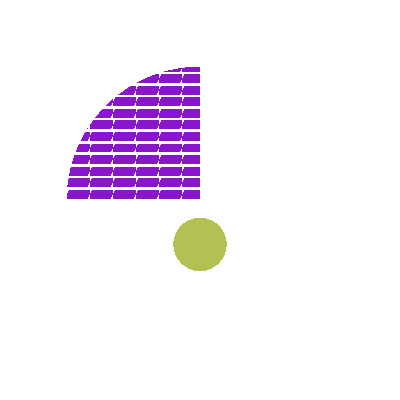

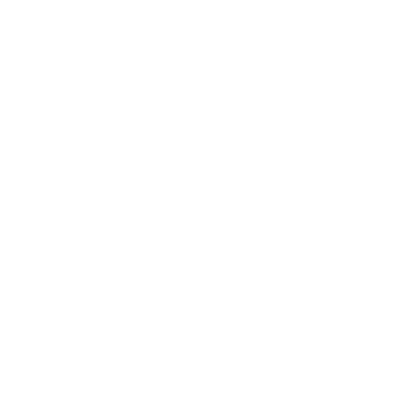

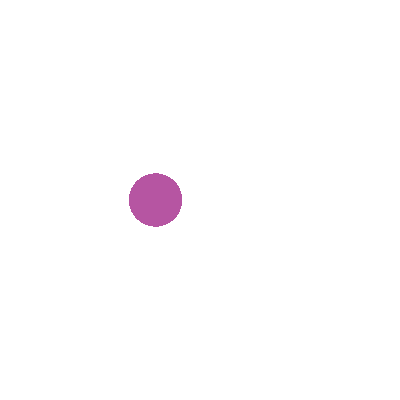

In [5]:
openmc.plot_inline(plots)